# 52. FM51 → yaw-robust correction-to-go FM (original topology only)

This notebook fine-tunes the **existing FM51 best checkpoint** on the original KAIST rig (`imu`, `lidar`, `lidar_right`), adding **common-body-frame Z-yaw augmentation** from Notebook 39. No synthetic sensor topology, noise, or LiDAR replacement is used. Both the current calibration and its truth target are rotated by the *same* rigid frame transform. Raw sensor measurements are unchanged.

**Preserved:** 50/50 analytical/on-policy correction-to-go supervision, normalized remaining-displacement velocity loss, differentiable 4-step endpoint loss, 16-step inference, fine/coarse priors, independent optimizer groups, resumable checkpoints. **Added:** optionally paired original/rotated views, small endpoint equivariance regularizer, independent stochastic yaw test, fixed controlled yaw×fault evaluation, FM51 comparison.

Recommended sequence: imports → settings → data → augmentations → geometry/gradient check → stochastic check → full training → held-out yaw evaluation. Stochastic training restores model weights; full training starts from FM51 or resumes **Notebook 52's own** `last.pt`. This notebook does not change `.py` files.

## 1. Imports and paths

In [1]:
from pathlib import Path
from dataclasses import asdict, fields, is_dataclass, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the nn-obs-calib repository root (must contain src/obscalib).")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.common_body_frame import CommonBodyFrameRandomizer
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationFlowIntegratorConfig, CalibrationFlowLossConfig, CalibrationPoolerConfig, MLPConfig, PooledCalibrationFlowConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch, TokenBatch
from obscalib.flow_matching.loss import calibration_velocity_loss
from obscalib.flow_matching.calibration_path import make_correction_to_go_flow_batch
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print("ROOT", ROOT, "| PyTorch", torch.__version__, "| CUDA", torch.cuda.is_available())


ROOT /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch 2.7.1+cu126 | CUDA True


## 2. Run configuration: one topology, signed Z-yaw curriculum

In [2]:
RUN_NAME = "kaist_pooled_calibration_fm.9_signed_z_yaw"
# This is the best checkpoint from Notebook 51. Change only if your saved run has a different name.
SOURCE_FM_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.8_topology_179" / "best.pt"
RUN_DIR = ROOT / "runs" / RUN_NAME
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / "best.pt", RUN_DIR / "last.pt"

SEED = 12345
TRAIN_AUG_SEED, VAL_AUG_SEED, TEST_AUG_SEED = 23456, 34567, 45678
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
MEASUREMENT_DIM = 6
WINDOW_DURATION_S, WINDOW_STRIDE_S = 5.0, 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE, NUM_WORKERS = 8, 0
HEAD_LEARNING_RATE, BACKBONE_LEARNING_RATE = 2e-5, 2e-6
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
GRADIENT_ACCUMULATION_STEPS = 4
FLOW_PATH_NUM_POINTS = 9
TRAIN_INTEGRATION_STEPS, TRAIN_INTEGRATION_METHOD = 4, "euler"
FM_INTEGRATION_STEPS, FM_INTEGRATION_METHOD = 16, "midpoint"
ABLATION_STEPS = (1, 2, 4, 8, 16, 32)
VELOCITY_LOSS_WEIGHT, ENDPOINT_LOSS_WEIGHT = 1.0, 0.2

# Physical augmentation and calibration prior. Only original sensor topology is permitted.
FINE_PRIOR_PROBABILITY = 0.50
FINE_ROTATION_MAX_RAD, FINE_ROTATION_SCALE_RAD = np.deg2rad(60.), np.deg2rad(30.)
FINE_TIME_OFFSET_MAX_S, FINE_TIME_OFFSET_SCALE_S = 0.5, 0.25
COARSE_TIME_OFFSET_MAX_S, COARSE_TIME_OFFSET_SCALE_S = 0.5, 0.25
STUDENT_T_DEGREES_OF_FREEDOM = 3
TRUE_ROTATION_MAX_RAD, TRUE_TIME_OFFSET_MAX_S = np.deg2rad(180.), 0.030

# FULL TRAINING: independent of stochastic preflight.
RUN_FULL_TRAINING = True       # Enable only after stochastic/preflight inspection.
RESUME_FULL_TRAINING = True    # Resume ONLY this Notebook 52's last.pt, including optimizer.
TRAIN_EPOCHS = 120
FULL_COARSE_MAX_DEG = 179.0
FULL_TRAIN_REGIME = "mixed"  # "fine", "coarse", "mixed"
FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT = 0.50, 0.50
TRAIN_PAIRED_VIEWS = True     # Original + same physical window in sampled common Z-yaw frame.
ROTATED_VIEW_WEIGHT = 1.0    # Paired loss = (L_original + weight * L_rotated) / (1 + weight)
EQUIVARIANCE_LOSS_WEIGHT = 0.05  # Additional endpoint equivariance regularizer (0 = two supervised views only).
MAX_TRAIN_BATCHES_PER_EPOCH, MAX_VAL_BATCHES_PER_EPOCH = None, None
LR_REDUCE_STEPS, LR_REDUCE_FACTOR = 8, 0.5
REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING = False

# Notebook 39-style signed yaw curriculum: every five epochs increase the maximum |yaw| by 10°.
# With Z-only axes, the randomizer samples BOTH positive and negative yaw.
FULL_YAW_PROBABILITY = 0.90
USE_YAW_CURRICULUM = True
FULL_FIXED_YAW_MAX_DEG = 180.0
FULL_YAW_SCHEDULE = tuple((1 + 2 * i, min(180., 10. * (i + 1))) for i in range(18))
# Validation intentionally uses the same FIXED full signed yaw range every epoch.
VAL_YAW_PROBABILITY, VAL_YAW_MAX_DEG = 1.0, 180.0
YAW_AXES = (False, False, True)

FULL_OBJECTIVE = dict(
    mode="mixed", off_path_probability=0.50, identity_probability=0.15,
    max_time=0.975, rotation_noise_std_rad=np.deg2rad(8.0),
    translation_noise_std_m=0.02, tau_noise_std_s=0.02,
    velocity_weight=VELOCITY_LOSS_WEIGHT, endpoint_weight=ENDPOINT_LOSS_WEIGHT,
    randomized_integration=True, randomized_query_times=True,
    on_policy_fraction=0.5, on_policy_steps=8,
    on_policy_max_time=0.875, on_policy_method="midpoint",
)


random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if DEVICE.type == "cuda": torch.cuda.manual_seed_all(SEED)
# for value in (STOCHASTIC_COARSE_MAX_DEG, FULL_COARSE_MAX_DEG):
#     assert 60. <= value < 180.
assert tuple(YAW_AXES) == (False, False, True)
assert (SOURCE_FM_CHECKPOINT.is_file()), f"Source FM51 checkpoint not found: {SOURCE_FM_CHECKPOINT}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Source FM51:", SOURCE_FM_CHECKPOINT)
# print("Stochastic:", STOCHASTIC_YAW_MODE, STOCHASTIC_COARSE_MAX_DEG, STOCHASTIC_STEPS)
print("Full yaw schedule:", FULL_YAW_SCHEDULE, "| enabled:", RUN_FULL_TRAINING)


Source FM51: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/best.pt
Full yaw schedule: ((1, 10.0), (3, 20.0), (5, 30.0), (7, 40.0), (9, 50.0), (11, 60.0), (13, 70.0), (15, 80.0), (17, 90.0), (19, 100.0), (21, 110.0), (23, 120.0), (25, 130.0), (27, 140.0), (29, 150.0), (31, 160.0), (33, 170.0), (35, 180.0)) | enabled: True


## 3. KAIST data (original three-sensor topology, unchanged)

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
assert len(set(ALL_SEQUENCE_NAMES)) == len(ALL_SEQUENCE_NAMES)

T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_right = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=float)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV required by 002.24 architecture: {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config, measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64, window_timestamp_dtype=DTYPE)

train_dataset, val_dataset, test_dataset = (make_dataset(names) for names in (TRAIN_NAMES, VAL_NAMES, TEST_NAMES))
for name, ds in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(ds.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"Unexpected calibration keys for {name}: {ds.calibration_keys}")
    print(name, len(ds), "windows")

train_shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)


train 2006 windows
validation 418 windows
test 699 windows


## 4. Physical truth and prior perturbations, followed by a shared Z-yaw frame rotation

In [4]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

fine_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=FINE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=FINE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
coarse_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(FULL_COARSE_MAX_DEG), distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=COARSE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.UNIFORM, scale=COARSE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

def augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def clone_with_current_calibration(window: WindowBatch, new_calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=new_calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)

# Probability that each calibration receives the ONE prior fault in a physical window.
# Keep original KAIST unchanged; emphasize the remaining real LiDAR in 2-IMU/1-LiDAR cases.
FAULT_KEY_WEIGHTS = {
    frozenset(("imu", "lidar", "lidar_right")): {"imu": 1.0, "lidar": 1.0, "lidar_right": 1.0},
    frozenset(("imu", "imu_synth", "lidar_right")): {"imu": 0.20, "imu_synth": 0.20, "lidar_right": 0.60},
    frozenset(("imu", "lidar", "imu_synth")): {"imu": 0.20, "lidar": 0.60, "imu_synth": 0.20},
}

FAULT_KEY_WEIGHTS = {frozenset(CALIBRATION_KEYS): {key: 1.0 for key in CALIBRATION_KEYS}}
def sample_fine_coarse_deltas(true_states, generator: torch.Generator, regime: str = "mixed"):
    if regime not in {"mixed", "fine", "coarse"}:
        raise ValueError(regime)

    keys = tuple(true_states)
    probability_by_key = FAULT_KEY_WEIGHTS.get(frozenset(keys))
    if probability_by_key is None:
        raise ValueError(f"No fault-selection weights for calibration keys {keys}")

    template = next(iter(true_states.values())).transform
    n = len(template)
    weights = torch.tensor([probability_by_key[key] for key in keys], device=template.device, dtype=torch.float32)
    weights = weights / weights.sum()
    selected_key_indices = torch.multinomial(weights, n, replacement=True, generator=generator)

    if regime == "mixed":
        fine_mask = torch.rand(n, device=template.device, generator=generator) < FINE_PRIOR_PROBABILITY
    else:
        fine_mask = torch.full((n,), regime == "fine", device=template.device, dtype=torch.bool)

    # Reuse the existing perturbers on single-key dictionaries. This preserves their
    # exact Student-t/uniform SO(3) and tau distributions while controlling key choice.
    xi, tau = {}, {}
    for key_index, key in enumerate(keys):
        singleton = {key: true_states[key]}
        if regime != "coarse":
            _, fine_xi, fine_tau = fine_prior_perturber(singleton, generator=generator)
        if regime != "fine":
            _, coarse_xi, coarse_tau = coarse_prior_perturber(singleton, generator=generator)

        if regime == "fine":
            chosen_xi, chosen_tau = fine_xi[key], fine_tau[key]
        elif regime == "coarse":
            chosen_xi, chosen_tau = coarse_xi[key], coarse_tau[key]
        else:
            chosen_xi = torch.where(fine_mask[:, None], fine_xi[key], coarse_xi[key])
            chosen_tau = torch.where(fine_mask[:, None], fine_tau[key], coarse_tau[key])

        selected = (selected_key_indices == key_index)[:, None]
        xi[key] = torch.where(selected, chosen_xi, torch.zeros_like(chosen_xi))
        tau[key] = torch.where(selected, chosen_tau, torch.zeros_like(chosen_tau))

    return xi, tau, fine_mask

def correction_targets(window: WindowBatch):
    if window.targets is None:
        raise ValueError("Expected truth targets after topology/true-calibration augmentation")
    targets_xi, targets_tau = {}, {}
    for key, state in window.current_calibration.items():
        target = window.targets[key]
        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Missing correction truth for {key}")
        targets_xi[key] = se3_log(target.next_transform @ torch.linalg.inv(state.transform))
        targets_tau[key] = target.next_time_offset - state.time_offset
    return targets_xi, targets_tau



from obscalib.augmentations.common_body_frame import CommonBodyFrameRandomizer
physical_augmenter = AugmentationPipeline(true_calibration_config)


@torch.no_grad()
def augment_original_window(base_window: WindowBatch, generator: torch.Generator, *, regime="mixed"):
    """Physical truth + exactly one calibration prior. Never replaces sensor streams."""
    physical = physical_augmenter(base_window, generator=generator).augmented_window
    assert tuple(physical.current_calibration) == CALIBRATION_KEYS
    xi, tau, _ = sample_fine_coarse_deltas(physical.current_calibration, generator, regime=regime)
    return clone_with_current_calibration(physical, apply_prior_perturbation(physical.current_calibration, xi, tau))


def make_yaw_randomizer(max_deg, probability=1.0):
    """Notebook 39 common-body-frame augmentation: only rotations about +Z, signed."""
    assert 0. <= probability <= 1.
    assert max_deg is None or 0. <= max_deg <= 180.
    rotation = None if max_deg is None else PerturbationMagnitudeConfig(maximum=np.deg2rad(float(max_deg)), distribution=PerturbationDistribution.UNIFORM)
    config = CommonBodyFrameRandomizationConfig(enabled=True, probability=probability, rotation_axes=YAW_AXES, rotation=rotation)
    return CommonBodyFrameRandomizer(config)


def training_yaw_cap(epoch):
    if not USE_YAW_CURRICULUM:
        return FULL_FIXED_YAW_MAX_DEG
    value = FULL_YAW_SCHEDULE[0][1]
    for first_epoch, maximum in FULL_YAW_SCHEDULE:
        if epoch < first_epoch: break
        value = maximum
    return value


def rotate_yaw_view(window, generator, yaw_randomizer):
    """Rotate both the CURRENT and TARGET calibrations, preserving raw sensor data."""
    rotated, _, H = yaw_randomizer(window, generator=generator)
    assert set(rotated.current_calibration) == set(window.current_calibration)
    return rotated, H


def rotate_twists(xi, H):
    """Adjoint for a rotation-only common-frame transform, twist order [omega, v]."""
    R = H[:, :3, :3]
    return torch.cat((torch.bmm(R, xi[:, :3, None]).squeeze(-1), torch.bmm(R, xi[:, 3:, None]).squeeze(-1)), dim=-1)


def rotate_window_fixed_yaw(window, yaw_degrees):
    """Deterministic counterpart of CommonBodyFrameRandomizer for evaluation."""
    sample = next(iter(window.current_calibration.values())).transform
    yaw = sample.new_tensor(np.deg2rad(yaw_degrees))
    co, si = torch.cos(yaw), torch.sin(yaw)
    H = torch.eye(4, device=sample.device, dtype=sample.dtype).unsqueeze(0).repeat(len(sample), 1, 1)
    H[:, 0, 0], H[:, 0, 1] = co, -si
    H[:, 1, 0], H[:, 1, 1] = si, co
    current = {key: replace(state, transform=H @ state.transform) for key, state in window.current_calibration.items()}
    targets = None if window.targets is None else {
        key: replace(target, next_transform=H @ target.next_transform)
        for key, target in window.targets.items()
    }
    return WindowBatch(streams=dict(window.streams), metadata=dict(window.metadata), current_calibration=current, targets=targets, dataset_indices=window.dataset_indices), H


print("Original topology only", CALIBRATION_KEYS, "| Fine and coarse priors unchanged.")


Original topology only ('imu', 'lidar', 'lidar_right') | Fine and coarse priors unchanged.


## 5. Training utilities and FM51 model

In [5]:
def topology_slice_batch(window: WindowBatch, positions: torch.Tensor) -> WindowBatch:
    n = len(next(iter(window.current_calibration.values())).transform)
    if positions.numel() == 0:
        raise ValueError("Cannot create an empty topology group")
    positions_cpu = positions.detach().cpu().tolist()
    original_indices = window.dataset_indices
    if isinstance(original_indices, torch.Tensor):
        selected_indices = original_indices.index_select(0, positions.to(device=original_indices.device))
    elif original_indices is not None and hasattr(original_indices, "__len__") and len(original_indices) == n:
        selected = [original_indices[i] for i in positions_cpu]
        selected_indices = tuple(selected) if isinstance(original_indices, tuple) else selected
    else:
        selected_indices = original_indices

    def select(item):
        if isinstance(item, torch.Tensor) and item.ndim > 0 and item.shape[0] == n:
            return item.index_select(0, positions.to(device=item.device))
        if is_dataclass(item) and not isinstance(item, type):
            updates = {field.name: (selected_indices if isinstance(item, WindowBatch) and field.name == "dataset_indices" else select(getattr(item, field.name))) for field in fields(item) if field.init}
            return replace(item, **updates)
        if isinstance(item, dict):
            return {key: select(value) for key, value in item.items()}
        return item

    return select(window)


In [6]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD, ablation_steps=ABLATION_STEPS),
    loss=CalibrationFlowLossConfig(rotation_scale_rad=np.deg2rad(5.0), translation_scale_m=0.05, time_offset_scale_s=0.05, rotation_weight=2.0, translation_weight=1.0, time_offset_weight=1.0, active_rotation_weight=0.75),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.freeze_feature_extractor(False)
fm_loss_weights = flow_config.loss.to_loss_weights()

for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body, fm_model.head):
    assert all(p.requires_grad for p in module.parameters())
print("FM checkpoint loaded:", SOURCE_FM_CHECKPOINT)
print("FM parameters:", sum(p.numel() for p in fm_model.parameters()), "trainable:", sum(p.numel() for p in fm_model.parameters() if p.requires_grad))


FM checkpoint loaded: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/best.pt
FM parameters: 2555399 trainable: 2555399


In [7]:
class _CapturedTokens(Exception):
    pass

class _TokenCaptureModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokens = None
        self.context = None

    def forward(self, tokens, calibration_context=None, **kwargs):
        self.tokens = tokens
        self.context = calibration_context
        raise _CapturedTokens()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
capture_model = _TokenCaptureModel()

def tokenize_window(window: WindowBatch):
    # Topology-dependent calibration key set/order MUST be decided after augmentation.
    calibration_keys = tuple(window.current_calibration)
    step = WindowStep(geometry_processor=geometry_processor, tokenizer=Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=calibration_keys), model=capture_model, calibration_updater=calibration_updater)
    capture_model.tokens = None
    capture_model.context = None
    try:
        step(window)
    except _CapturedTokens:
        pass
    if capture_model.tokens is None:
        raise RuntimeError("WindowStep did not call model: failed to capture tokens")
    if tuple(capture_model.tokens.calibration_keys) != calibration_keys:
        raise AssertionError((calibration_keys, capture_model.tokens.calibration_keys))
    return capture_model.tokens, capture_model.context

def flow_supervision(window: WindowBatch, *, generator: torch.Generator, model=None):
    model = fm_model if model is None else model
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
    output = model.forward_flow_matching(tokens, target_xi, target_tau, calibration_context=context, generator=generator)
    loss = calibration_velocity_loss(output.predicted_velocity, output.flow_batch.target_velocity, weights=fm_loss_weights)
    return loss, output

@torch.no_grad()
def model_predictions(model, window, steps=FM_INTEGRATION_STEPS):
    tokens, context = tokenize_window(window)
    if isinstance(model, PooledCalibrationFlowModel):
        return model(tokens, context, num_steps=steps, method=FM_INTEGRATION_METHOD)
    return model(tokens, context)

from dataclasses import dataclass
from obscalib.flow_matching.lie_integrator import integrate_calibration_flow, CalibrationFlowResult

@dataclass
class JointFMEndpointLoss:
    total: torch.Tensor
    velocity: object
    endpoint: torch.Tensor
    endpoint_rotation: torch.Tensor
    endpoint_translation: torch.Tensor
    endpoint_tau: torch.Tensor
    lidar_active_rotation_deg: torch.Tensor
    lidar_healthy_rotation_deg: torch.Tensor

    def detached_metrics(self):
        metrics = self.velocity.detached_metrics()
        metrics.update({
            "loss_combined_total": float(self.total.detach()),
            "loss_endpoint_total": float(self.endpoint.detach()),
            "loss_endpoint_rotation": float(self.endpoint_rotation.detach()),
            "loss_endpoint_translation": float(self.endpoint_translation.detach()),
            "loss_endpoint_time_offset": float(self.endpoint_tau.detach()),
            "endpoint_lidar_active_rotation_deg": float(self.lidar_active_rotation_deg.detach()),
            "endpoint_lidar_healthy_rotation_deg": float(self.lidar_healthy_rotation_deg.detach()),
        })
        return metrics


def endpoint_loss_from_integration(window, flow_result, keys, target_xi, *, weights):
    """Physical corrected extrinsics and clocks; no detach anywhere on predicted path."""
    current = torch.stack([window.current_calibration[key].transform for key in keys], dim=1)
    desired = torch.stack([window.targets[key].next_transform for key in keys], dim=1)
    current_tau = torch.stack([window.current_calibration[key].time_offset for key in keys], dim=1)
    desired_tau = torch.stack([window.targets[key].next_time_offset for key in keys], dim=1)
    corrected = flow_result.correction_transform @ current
    predicted_tau = current_tau + flow_result.delta_tau

    # SO(3) geodesic angle is stable near identity and bounded by pi.
    residual_rotation = desired[..., :3, :3] @ corrected[..., :3, :3].transpose(-1, -2)
    skew = torch.stack((
        residual_rotation[..., 2, 1] - residual_rotation[..., 1, 2],
        residual_rotation[..., 0, 2] - residual_rotation[..., 2, 0],
        residual_rotation[..., 1, 0] - residual_rotation[..., 0, 1],
    ), dim=-1)
    sin_angle = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_angle = 0.5 * (residual_rotation.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    rotation_angle = torch.atan2(sin_angle, cos_angle)
    translation_error = corrected[..., :3, 3] - desired[..., :3, 3]
    tau_error = predicted_tau - desired_tau

    rotation_loss = (rotation_angle / weights.rotation_scale_rad).square().mean()
    translation_loss = (translation_error / weights.translation_scale_m).square().mean()
    tau_loss = (tau_error / weights.time_offset_scale_s).square().mean()
    combined = weights.rotation_weight * rotation_loss + weights.translation_weight * translation_loss + weights.time_offset_weight * tau_loss

    active_angles, healthy_angles = [], []
    for index, key in enumerate(keys):
        if key.startswith("lidar"):
            active_mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
            if bool(active_mask.any()): active_angles.append(torch.rad2deg(rotation_angle[:, index][active_mask]))
            if bool((~active_mask).any()): healthy_angles.append(torch.rad2deg(rotation_angle[:, index][~active_mask]))
    nan_metric = rotation_angle.detach().new_tensor(float("nan"))
    active = torch.cat(active_angles).mean() if active_angles else nan_metric
    healthy = torch.cat(healthy_angles).mean() if healthy_angles else nan_metric
    return combined, rotation_loss, translation_loss, tau_loss, active, healthy


def stratified_flow_grid(reference, num_points, max_time, *, generator=None, randomized=True):
    """Return time queries in [0, max_time], always supervising t=0.

    Evaluation uses a fixed grid; training samples one time in every interior
    stratum rather than learning only a handful of fixed interpolation times.
    """
    if num_points < 2:
        raise ValueError("At least two time points required")
    if randomized:
        increments = (torch.arange(1, num_points, device=reference.device, dtype=reference.dtype) +
                      torch.rand(num_points - 1, device=reference.device, dtype=reference.dtype, generator=generator))
        return torch.cat((reference.new_zeros(1), max_time * increments / num_points))
    return torch.linspace(0, max_time, num_points, device=reference.device, dtype=reference.dtype)


def integrate_training_correction(model, shared, stacked_context, *, generator=None, randomized=True):
    """Train with right-composed Lie-Euler and optionally jittered step boundaries.

    Uses the same update rule as integrate_calibration_flow, with actual dt_k.
    Jitter is disabled in deterministic validation; inference remains unchanged.
    """
    if not randomized:
        return model.integrate_from_features(shared, stacked_context, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    if TRAIN_INTEGRATION_METHOD != "euler":
        raise ValueError("Randomized training intervals currently require Lie-Euler")
    num_steps = TRAIN_INTEGRATION_STEPS
    b, c, _ = shared.shape
    grid = torch.linspace(0, 1, num_steps + 1, device=shared.device, dtype=shared.dtype)
    if num_steps > 1:
        perturb = (torch.rand(num_steps - 1, device=shared.device, dtype=shared.dtype, generator=generator) - 0.5) / num_steps
        grid = torch.cat((grid[:1], grid[1:-1] + perturb, grid[-1:]))
    D = torch.eye(4, dtype=shared.dtype, device=shared.device).expand(b, c, 4, 4).clone()
    tau = shared.new_zeros(b, c, 1)
    for k in range(num_steps):
        dt = grid[k + 1] - grid[k]
        xi = shared.new_zeros(b, c, 6) if k == 0 else se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6)
        t = grid[k].expand(b, c, 1)
        v = model.velocity_from_features(shared, xi, tau, t, stacked_context)
        D = D @ se3_exp((dt * v[..., :6]).reshape(-1, 6)).reshape(b, c, 4, 4)
        tau = tau + dt * v[..., 6:]
    return CalibrationFlowResult(se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6), tau, D)


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Correction-to-go velocity MSE and optional differentiable endpoint loss.

    Encode each physical window ONCE and share features over all correction
    queries and integration steps. Targets have no gradients; the predicted
    field retains gradients through all model components.
    """
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)
    batch_size, num_calibrations, feature_dim = shared.shape
    num_points = FLOW_PATH_NUM_POINTS
    grid = stratified_flow_grid(shared, num_points, objective["max_time"], generator=generator, randomized=model.training and objective["randomized_query_times"])
    times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)
    with torch.no_grad():
        path_batch = make_correction_to_go_flow_batch(
            delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
            delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
            time=times, mode=objective["mode"],
            off_path_probability=objective["off_path_probability"],
            identity_probability=objective["identity_probability"],
            rotation_noise_std_rad=objective["rotation_noise_std_rad"],
            translation_noise_std_m=objective["translation_noise_std_m"],
            tau_noise_std_s=objective["tau_noise_std_s"],
            max_time=objective["max_time"], generator=generator,
        )
    repeated_shared = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, feature_dim)
    repeated_context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])
    predicted = model.velocity_from_features(
        repeated_shared,
        path_batch.correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        path_batch.correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        path_batch.time.reshape(num_points * batch_size, num_calibrations, 1),
        repeated_context,
    ).reshape(num_points, batch_size, num_calibrations, 7)
    # Active rotation is defined by the original corrupted sensor, NOT by the
    # off-path recovery velocity of an otherwise healthy calibration.
    active_mask = (torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad)
    active_mask = active_mask.unsqueeze(0).expand(num_points, -1, -1)
    velocity = calibration_velocity_loss(predicted, path_batch.target_velocity, weights=fm_loss_weights, active_rotation_mask=active_mask)

    # The field integrates along its own trajectory, not the teacher path.
    # No torch.no_grad here: train-time endpoint loss must reach the head and backbone.
    result = integrate_training_correction(model, shared, stacked_context, generator=generator,
        randomized=model.training and objective["randomized_integration"])
    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy = endpoint_loss_from_integration(window, result, keys, target_xi, weights=fm_loss_weights)
    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint
    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite correction-to-go joint loss")
    return JointFMEndpointLoss(total, velocity, endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy), result


from obscalib.flow_matching.loss import CalibrationFlowLoss


@dataclass
class OnPolicyJointFMEndpointLoss(JointFMEndpointLoss):
    analytical_velocity_total: torch.Tensor
    on_policy_velocity_total: torch.Tensor

    def detached_metrics(self):
        metrics = super().detached_metrics()
        metrics["loss_fm_analytical_total"] = float(self.analytical_velocity_total.detach())
        metrics["loss_fm_on_policy_total"] = float(self.on_policy_velocity_total.detach())
        return metrics


def _velocity_at_flow_states(model, shared, stacked_context, correction_xi, correction_tau, times):
    """Evaluate the trainable velocity head over multiple correction states."""
    num_points, batch_size, num_calibrations, _ = correction_xi.shape
    hidden_dim = shared.shape[-1]

    features = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, hidden_dim)
    context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])

    predicted = model.velocity_from_features(
        features,
        correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        times.reshape(num_points * batch_size, num_calibrations, 1),
        context,
    )
    return predicted.reshape(num_points, batch_size, num_calibrations, 7)


def _rollout_correction_to_go_states(model, shared, stacked_context, delta_xi, delta_tau, *, num_steps, max_time, method):
    """Integrate the current model without autograd and supervise its visited states."""
    if not (0.0 <= max_time < 1.0):
        raise ValueError("on_policy_max_time must be in [0, 1).")
    if num_steps < 1:
        raise ValueError("on_policy_steps must be positive.")

    with torch.no_grad():
        context = None if stacked_context is None else stacked_context.detach()
        result = model.integrate_from_features(
            shared.detach(), context,
            num_steps=num_steps, method=method, record_trajectory=True,
        )

        states = tuple(state for state in result.trajectory if state.time <= max_time + 1e-7)
        if not states or abs(states[0].time) > 1e-7:
            raise RuntimeError("Rollout trajectory must begin at identity.")

        num_points = len(states)
        batch_size, num_calibrations, _ = delta_xi.shape

        D = torch.stack([state.correction_transform for state in states], dim=0)
        tau = torch.stack([state.correction_tau for state in states], dim=0)
        times = delta_tau.new_tensor([state.time for state in states]).view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        target_D = se3_exp(delta_xi.reshape(-1, 6)).reshape(batch_size, num_calibrations, 4, 4)
        remaining_D = torch.linalg.solve(D, target_D.unsqueeze(0).expand_as(D))
        remaining_xi = se3_log(remaining_D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        remaining_time = 1.0 - times
        target_velocity = torch.cat(
            (remaining_xi / remaining_time, (delta_tau.unsqueeze(0) - tau) / remaining_time),
            dim=-1,
        )
        correction_xi = se3_log(D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        if not bool(torch.isfinite(target_velocity).all()):
            raise FloatingPointError("Nonfinite on-policy correction-to-go target.")

        return correction_xi, tau, times, target_velocity


def _mix_calibration_velocity_losses(analytical, on_policy, fraction):
    """Retain the existing CalibrationFlowLoss interface and metrics."""
    a, b = 1.0 - fraction, fraction
    return CalibrationFlowLoss(
        total=a * analytical.total + b * on_policy.total,
        rotation=a * analytical.rotation + b * on_policy.rotation,
        translation=a * analytical.translation + b * on_policy.translation,
        time_offset=a * analytical.time_offset + b * on_policy.time_offset,
        active_rotation=a * analytical.active_rotation + b * on_policy.active_rotation,
        num_active_rotations=analytical.num_active_rotations + on_policy.num_active_rotations,
    )


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Analytical CTG + detached on-policy CTG + differentiable endpoint loss."""
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    fraction = float(objective.get("on_policy_fraction", 0.5))

    if not (0.0 <= fraction <= 1.0):
        raise ValueError("on_policy_fraction must be in [0, 1].")

    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    # Compute sensor features ONCE. Gradients through these features are retained.
    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)

    batch_size, num_calibrations, _ = shared.shape
    active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad

    # ---------------------------------------------------------
    # 1. Original analytical correction-to-go supervision
    # ---------------------------------------------------------

    analytical_loss = None

    if fraction < 1.0:
        num_points = FLOW_PATH_NUM_POINTS
        grid = stratified_flow_grid(
            shared, num_points, objective["max_time"], generator=generator,
            randomized=model.training and objective["randomized_query_times"],
        )
        times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        with torch.no_grad():
            path = make_correction_to_go_flow_batch(
                delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
                delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
                time=times,
                mode=objective["mode"],
                off_path_probability=objective["off_path_probability"],
                identity_probability=objective["identity_probability"],
                rotation_noise_std_rad=objective["rotation_noise_std_rad"],
                translation_noise_std_m=objective["translation_noise_std_m"],
                tau_noise_std_s=objective["tau_noise_std_s"],
                max_time=objective["max_time"],
                generator=generator,
            )

        predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            path.correction_xi, path.correction_tau, path.time,
        )
        analytical_loss = calibration_velocity_loss(
            predicted, path.target_velocity,
            weights=fm_loss_weights,
            active_rotation_mask=active.unsqueeze(0).expand(num_points, -1, -1),
        )

    # ---------------------------------------------------------
    # 2. Generate detached states from model's OWN trajectory
    # ---------------------------------------------------------

    on_policy_loss = None

    if fraction > 0.0:
        rollout_xi, rollout_tau, rollout_times, rollout_target = _rollout_correction_to_go_states(
            model, shared, stacked_context, delta_xi, delta_tau,
            num_steps=int(objective.get("on_policy_steps", 8)),
            max_time=float(objective.get("on_policy_max_time", 0.875)),
            method=objective.get("on_policy_method", "midpoint"),
        )

        # This forward pass DOES retain gradients through all neural components.
        rollout_predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            rollout_xi, rollout_tau, rollout_times,
        )

        on_policy_loss = calibration_velocity_loss(
            rollout_predicted, rollout_target,
            weights=fm_loss_weights,
            active_rotation_mask=active.unsqueeze(0).expand(rollout_xi.shape[0], -1, -1),
        )

    # ---------------------------------------------------------
    # 3. Combine both velocity objectives
    # ---------------------------------------------------------

    if analytical_loss is None:
        velocity = on_policy_loss
    elif on_policy_loss is None:
        velocity = analytical_loss
    else:
        velocity = _mix_calibration_velocity_losses(analytical_loss, on_policy_loss, fraction)

    # ---------------------------------------------------------
    # 4. Original differentiable 4-step endpoint objective
    # ---------------------------------------------------------

    result = integrate_training_correction(
        model, shared, stacked_context,
        generator=generator,
        randomized=model.training and objective["randomized_integration"],
    )

    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, lidar_active, lidar_healthy = endpoint_loss_from_integration(
        window, result, keys, target_xi, weights=fm_loss_weights,
    )

    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint
    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite on-policy joint loss.")

    zero = total.detach().new_zeros(())
    losses = OnPolicyJointFMEndpointLoss(
        total=total,
        velocity=velocity,
        endpoint=endpoint,
        endpoint_rotation=endpoint_rotation,
        endpoint_translation=endpoint_translation,
        endpoint_tau=endpoint_tau,
        lidar_active_rotation_deg=lidar_active,
        lidar_healthy_rotation_deg=lidar_healthy,
        analytical_velocity_total=analytical_loss.total if analytical_loss is not None else zero,
        on_policy_velocity_total=on_policy_loss.total if on_policy_loss is not None else zero,
    )
    return losses, result


In [8]:

def remaining_displacement_velocity_loss(predicted, target, times, active_mask):
    """Time-weighted CTG loss, with branch-wise weight normalization.

    The target remains velocity; multiplying BOTH arguments by remaining time
    penalizes predicted remaining displacement without changing the pointwise optimum.
    """
    if predicted.shape != target.shape or times.shape != predicted.shape[:-1] + (1,):
        raise ValueError("Inconsistent predicted, target, or time shapes")

    remaining = 1.0 - times
    if bool((remaining <= 0).any()):
        raise ValueError("Correction-to-go supervision requires t < 1")

    # Keep the mean squared time weight equal to 1 for each branch.
    scale = remaining / remaining.square().mean().sqrt().clamp_min(1e-8)

    return calibration_velocity_loss(
        predicted * scale,
        target * scale,
        weights=fm_loss_weights,
        active_rotation_mask=active_mask,
    )


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Normalized remaining-displacement supervision on analytical and rollout states.

    Sensor features are encoded once. On-policy trajectory generation is detached,
    but supervised velocity predictions retain gradients through all model blocks.
    """
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    fraction = float(objective.get("on_policy_fraction", 0.5))

    if not (0.0 <= fraction <= 1.0):
        raise ValueError("on_policy_fraction must be in [0, 1].")

    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)

    batch_size, num_calibrations, _ = shared.shape
    active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad

    # ---------------------------------------------------------
    # 1. Analytical CTG supervision, up to t=0.975
    # ---------------------------------------------------------

    analytical_loss = None

    if fraction < 1.0:
        num_points = FLOW_PATH_NUM_POINTS
        grid = stratified_flow_grid(
            shared, num_points, objective["max_time"],
            generator=generator,
            randomized=model.training and objective["randomized_query_times"],
        )
        times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        with torch.no_grad():
            path = make_correction_to_go_flow_batch(
                delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
                delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
                time=times,
                mode=objective["mode"],
                off_path_probability=objective["off_path_probability"],
                identity_probability=objective["identity_probability"],
                rotation_noise_std_rad=objective["rotation_noise_std_rad"],
                translation_noise_std_m=objective["translation_noise_std_m"],
                tau_noise_std_s=objective["tau_noise_std_s"],
                max_time=objective["max_time"],
                generator=generator,
            )

        predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            path.correction_xi, path.correction_tau, path.time,
        )

        analytical_loss = remaining_displacement_velocity_loss(
            predicted,
            path.target_velocity,
            path.time,
            active.unsqueeze(0).expand(num_points, -1, -1),
        )

    # ---------------------------------------------------------
    # 2. On-policy CTG supervision, up to t=0.875
    # ---------------------------------------------------------

    on_policy_loss = None

    if fraction > 0.0:
        rollout_xi, rollout_tau, rollout_times, rollout_target = _rollout_correction_to_go_states(
            model, shared, stacked_context, delta_xi, delta_tau,
            num_steps=int(objective.get("on_policy_steps", 8)),
            max_time=float(objective.get("on_policy_max_time", 0.875)),
            method=objective.get("on_policy_method", "midpoint"),
        )

        rollout_predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            rollout_xi, rollout_tau, rollout_times,
        )

        on_policy_loss = remaining_displacement_velocity_loss(
            rollout_predicted,
            rollout_target,
            rollout_times,
            active.unsqueeze(0).expand(rollout_xi.shape[0], -1, -1),
        )

    # ---------------------------------------------------------
    # 3. Combine remaining-displacement losses
    # ---------------------------------------------------------

    if analytical_loss is None:
        velocity = on_policy_loss
    elif on_policy_loss is None:
        velocity = analytical_loss
    else:
        velocity = _mix_calibration_velocity_losses(analytical_loss, on_policy_loss, fraction)

    # ---------------------------------------------------------
    # 4. Differentiable endpoint loss, unchanged
    # ---------------------------------------------------------

    result = integrate_training_correction(
        model, shared, stacked_context,
        generator=generator,
        randomized=model.training and objective["randomized_integration"],
    )

    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, lidar_active, lidar_healthy = endpoint_loss_from_integration(
        window, result, keys, target_xi, weights=fm_loss_weights,
    )

    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint

    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite correction-to-go joint loss")

    zero = total.detach().new_zeros(())
    losses = OnPolicyJointFMEndpointLoss(
        total=total,
        velocity=velocity,
        endpoint=endpoint,
        endpoint_rotation=endpoint_rotation,
        endpoint_translation=endpoint_translation,
        endpoint_tau=endpoint_tau,
        lidar_active_rotation_deg=lidar_active,
        lidar_healthy_rotation_deg=lidar_healthy,
        analytical_velocity_total=analytical_loss.total if analytical_loss is not None else zero,
        on_policy_velocity_total=on_policy_loss.total if on_policy_loss is not None else zero,
    )

    return losses, result


## 6. Source-preserving geometry, oracle, and gradient checks

In [9]:
test_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
with torch.no_grad():
    base = augment_original_window(test_base, augmentation_generator(TRAIN_AUG_SEED+1), regime="fine")
    rotated, H = rotate_yaw_view(base, augmentation_generator(TRAIN_AUG_SEED+2), make_yaw_randomizer(180., 1.))
    R = H[:, :3, :3]
    for stream_key in base.streams:
        a, b = base.streams[stream_key], rotated.streams[stream_key]
        torch.testing.assert_close(a.values, b.values, rtol=0, atol=0)
        torch.testing.assert_close(a.timestamps, b.timestamps, rtol=0, atol=0)
        if a.interval_start_timestamps is not None:
            torch.testing.assert_close(a.interval_start_timestamps, b.interval_start_timestamps, rtol=0, atol=0)
    for key in CALIBRATION_KEYS:
        ac, bc = base.current_calibration[key], rotated.current_calibration[key]
        torch.testing.assert_close(bc.transform, H @ ac.transform, rtol=3e-5, atol=3e-5)
        torch.testing.assert_close(bc.time_offset, ac.time_offset, rtol=0, atol=0)
        ta, tb = base.targets[key], rotated.targets[key]
        torch.testing.assert_close(tb.next_transform, H @ ta.next_transform, rtol=3e-5, atol=3e-5)
        xi_a, tau_a = correction_targets(base)
        xi_b, tau_b = correction_targets(rotated)
        torch.testing.assert_close(xi_b[key], rotate_twists(xi_a[key], H), rtol=3e-3, atol=4e-4)
        torch.testing.assert_close(tau_b[key], tau_a[key], rtol=0, atol=1e-6)
        for other in CALIBRATION_KEYS:
            ra = torch.linalg.solve(ac.transform, base.current_calibration[other].transform)
            rb = torch.linalg.solve(bc.transform, rotated.current_calibration[other].transform)
            torch.testing.assert_close(ra, rb, atol=5e-5, rtol=5e-5)
    for window in (base, rotated):
        xi, tau = correction_targets(window)
        tokens, context = tokenize_window(window)
        assert tuple(tokens.calibration_keys) == CALIBRATION_KEYS and tokens.x.shape[-1] == 8
        target_vel = torch.stack([torch.cat((xi[key], tau[key]), dim=-1) for key in CALIBRATION_KEYS], dim=1)
        ref = target_vel.new_zeros(*target_vel.shape[:-1], 8)
        oracle = integrate_calibration_flow(lambda state_xi, state_tau, t: target_vel, ref, num_steps=4, method="euler")
        for j, key in enumerate(CALIBRATION_KEYS):
            torch.testing.assert_close(oracle.correction_transform[:, j] @ window.current_calibration[key].transform, window.targets[key].next_transform, atol=5e-4, rtol=5e-4)

fm_model.train()
fm_model.zero_grad(set_to_none=True)
grad_loss, _ = joint_flow_endpoint_supervision(rotated, generator=augmentation_generator(TRAIN_AUG_SEED+3))
grad_loss.total.backward()
for component in ("transformer_encoder", "pooler", "mlp_body", "head"):
    grads = [p.grad for p in getattr(fm_model, component).parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(torch.isfinite(g).all() for g in grads)
    print(component, "gradient norm", f"{sum(g.square().sum().item() for g in grads)**0.5:.4g}")
fm_model.zero_grad(set_to_none=True)
fm_model.eval()
print("PASS: raw measurements unchanged, physical SE3 and tau truth consistently rotated, oracle endpoints, gradients")


transformer_encoder gradient norm 2091
pooler gradient norm 183.4
mlp_body gradient norm 310.4
head gradient norm 343.2
PASS: raw measurements unchanged, physical SE3 and tau truth consistently rotated, oracle endpoints, gradients


## 7. Paired FM objective and correctly normalized fine/coarse weighting

In [10]:
def set_coarse_angle(angle_deg):
    """Rebuild only the coarse uniform prior; do not change the fine distribution."""
    global COARSE_ROTATION_MAX_RAD, coarse_prior_config, coarse_prior_perturber
    angle_deg = float(angle_deg)
    if not (60.0 <= angle_deg < 180.0):
        raise ValueError("Coarse maximum angle must be in [60,180) degrees")
    COARSE_ROTATION_MAX_RAD = np.deg2rad(angle_deg)
    coarse_prior_config = replace(coarse_prior_config, rotation=replace(coarse_prior_config.rotation, maximum=COARSE_ROTATION_MAX_RAD))
    coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)


def weighted_regime_groups(base_window, generator, regime):
    """Split a homogeneous topology batch before augmentation, recording the actual sampled regime."""
    if regime not in ("mixed", "fine", "coarse"):
        raise ValueError(regime)
    n = len(next(iter(base_window.current_calibration.values())).transform)
    if regime != "mixed":
        return [(regime, base_window)]
    device = next(iter(base_window.current_calibration.values())).transform.device
    fine_mask = torch.rand(n, device=device, generator=generator) < FINE_PRIOR_PROBABILITY
    return [(name, topology_slice_batch(base_window, positions))
            for name, positions in (("fine", fine_mask.nonzero(as_tuple=True)[0]),
                                    ("coarse", (~fine_mask).nonzero(as_tuple=True)[0])) if positions.numel()]


def regime_loss_multiplier(regime, sampling_regime, fine_weight, coarse_weight):
    """Importance-adjusted multiplier for alpha_f * E[L_f] + alpha_c * E[L_c].

    For mixed sampling p(fine)=FINE_PRIOR_PROBABILITY, alpha weights are explicit
    desired objective weights. Setting both to .5 yields the original unbiased
    objective with 50/50 sampling. Single-regime training uses multiplier 1.
    """
    if sampling_regime != "mixed":
        return 1.0
    probability = FINE_PRIOR_PROBABILITY if regime == "fine" else 1.0 - FINE_PRIOR_PROBABILITY
    weight = fine_weight if regime == "fine" else coarse_weight
    return float(weight / (fine_weight + coarse_weight) / probability)

# At fixed 50/50 sampling, these settings recover the original objective.
assert np.isclose(regime_loss_multiplier("fine", "mixed", 0.5, 0.5), 1.0)
assert np.isclose(regime_loss_multiplier("coarse", "mixed", 0.5, 0.5), 1.0)
set_coarse_angle(FULL_COARSE_MAX_DEG)

def paired_endpoint_equivariance(base_result, rotated_result, H):
    """Equivariance of INTEGRATED correction, not just intermediate velocities.

    Correct transformation: D_rot = H @ D_base @ inv(H).  Rotation-only H.
    Angular and translation components use the same normalization as FM loss.
    """
    D0, D1 = base_result.correction_transform, rotated_result.correction_transform
    expected = H.unsqueeze(1) @ D0 @ torch.linalg.inv(H).unsqueeze(1)
    residual = torch.linalg.solve(expected, D1)
    twist = se3_log(residual.reshape(-1, 4, 4)).reshape(*D0.shape[:2], 6)
    rot_err = (twist[..., :3] / fm_loss_weights.rotation_scale_rad).square().mean()
    trans_err = (twist[..., 3:] / fm_loss_weights.translation_scale_m).square().mean()
    tau_err = ((base_result.delta_tau - rotated_result.delta_tau) / fm_loss_weights.time_offset_scale_s).square().mean()
    return fm_loss_weights.rotation_weight * rot_err + fm_loss_weights.translation_weight * trans_err + fm_loss_weights.time_offset_weight * tau_err


def evaluate_paired_objective(window, *, generator, frame_randomizer, regime, objective, paired=True):
    """Two supervised coordinate views of one physical sample; optional equivariance."""
    rotated, H = rotate_yaw_view(window, generator, frame_randomizer)
    loss_rotated, result_rotated = joint_flow_endpoint_supervision(rotated, generator=generator, objective=objective)
    if not paired:
        return loss_rotated.total, dict(rotated=float(loss_rotated.total.detach()), original=float('nan'), equivariance=0.0, endpoint=float(loss_rotated.endpoint.detach()), velocity=float(loss_rotated.velocity.total.detach()), lidar_active=float(loss_rotated.lidar_active_rotation_deg.detach()), lidar_healthy=float(loss_rotated.lidar_healthy_rotation_deg.detach()))
    loss_original, result_original = joint_flow_endpoint_supervision(window, generator=generator, objective=objective)
    equiv = paired_endpoint_equivariance(result_original, result_rotated, H) if EQUIVARIANCE_LOSS_WEIGHT else loss_original.total.new_zeros(())
    supervised = (loss_original.total + ROTATED_VIEW_WEIGHT * loss_rotated.total) / (1. + ROTATED_VIEW_WEIGHT)
    total = supervised + EQUIVARIANCE_LOSS_WEIGHT * equiv
    return total, dict(
        rotated=float(loss_rotated.total.detach()), original=float(loss_original.total.detach()),
        equivariance=float(equiv.detach()), endpoint=float(loss_rotated.endpoint.detach()),
        velocity=float(loss_rotated.velocity.total.detach()),
        lidar_active=float(loss_rotated.lidar_active_rotation_deg.detach()),
        lidar_healthy=float(loss_rotated.lidar_healthy_rotation_deg.detach()),
    )

set_coarse_angle(FULL_COARSE_MAX_DEG)


## 8. Stochastic preflight: fixed or scheduled signed yaw (weights restored afterward)

In [ ]:
@torch.no_grad()
def fixed_precheck_evaluation(model, eval_windows):
    """Same physical examples and exact yaw angles at every diagnostic step."""
    was_training = model.training
    model.eval()
    rows = []
    try:
        for (regime, yaw), window in eval_windows.items():
            tokens, context = tokenize_window(window)
            prediction = model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
            xi, _ = correction_targets(window)
            for key in CALIBRATION_KEYS:
                current = window.current_calibration[key].transform
                desired = window.targets[key].next_transform
                corrected = se3_exp(prediction.predictions[key].delta_xi) @ current
                R = desired[:, :3, :3] @ corrected[:, :3, :3].transpose(-1, -2)
                sine = .5 * torch.linalg.vector_norm(torch.stack((R[:,2,1]-R[:,1,2], R[:,0,2]-R[:,2,0], R[:,1,0]-R[:,0,1]), -1), dim=-1)
                cosine = .5 * (R.diagonal(dim1=-2, dim2=-1).sum(dim=-1)-1.)
                errors = torch.rad2deg(torch.atan2(sine, cosine))
                active = torch.linalg.vector_norm(xi[key][:, :3], dim=-1) > 1e-6
                for role, mask in (("active", active), ("healthy", ~active)):
                    if bool(mask.any()):
                        rows.append(dict(regime=regime, yaw_deg=yaw, key=key, role=role, mean_deg=float(errors[mask].mean()), n=int(mask.sum())))
    finally:
        model.train(was_training)
    return pd.DataFrame(rows)


# STOCHASTIC ONLY: independent yaw and coarse-angle controls, source weights restored afterward.
RUN_STOCHASTIC_CHECK = True
STOCHASTIC_STEPS, STOCHASTIC_REPORT_EVERY = 150, 10
STOCHASTIC_WINDOWS = 16         # min(16, BATCH_SIZE)
STOCHASTIC_TRAIN_REGIME = "mixed"
STOCHASTIC_COARSE_MAX_DEG = 179.0
STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT = 0.5, 0.5
STOCHASTIC_HEAD_LR, STOCHASTIC_BACKBONE_LR = 5e-5, 5e-6
STOCHASTIC_YAW_MODE = "scheduled"  # "fixed" or "scheduled"
STOCHASTIC_FIXED_YAW_MAX_DEG = 180.0
STOCHASTIC_YAW_START_DEG, STOCHASTIC_YAW_INCREMENT_DEG = 10.0, 10.0
STOCHASTIC_STEPS_PER_YAW = 5
STOCHASTIC_YAW_PROBABILITY = 0.90
STOCHASTIC_PAIRED_VIEWS = True
STOCHASTIC_SAVE_CANDIDATE = True
STOCHASTIC_SEED, STOCHASTIC_EVAL_SEED = TRAIN_AUG_SEED + 200000, VAL_AUG_SEED + 300000
STOCHASTIC_OBJECTIVE = dict(FULL_OBJECTIVE)
STOCHASTIC_CHECK_PASSED = None
precheck_history, precheck_final = [], None

if DEVICE.type == "cuda": torch.cuda.empty_cache()

if RUN_STOCHASTIC_CHECK:
    index = np.unique(np.linspace(0, len(train_dataset)-1, STOCHASTIC_WINDOWS).astype(int))
    small_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in index]), DEVICE, dtype=DTYPE)
    # Fixed validation cases: independent of stochastic training yaw schedule and random seeds.
    fixed_cases = {}
    for reg_idx, regime in enumerate(("fine", "coarse")):
        raw = augment_original_window(small_base, augmentation_generator(STOCHASTIC_EVAL_SEED + reg_idx), regime=regime)
        for yaw in (0., 90., 180., 270.):
            fixed_cases[(regime, yaw)] = rotate_window_fixed_yaw(raw, yaw)[0]
    saved_weights = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
    saved_mode = fm_model.training
    saved_cpu_rng = torch.random.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None
    saved_numpy_rng, saved_python_rng = np.random.get_state(), random.getstate()
    previous_coarse_deg = np.rad2deg(COARSE_ROTATION_MAX_RAD)
    diagnostic_optimizer = None
    try:
        load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
        set_coarse_angle(STOCHASTIC_COARSE_MAX_DEG)
        diagnostic_optimizer = torch.optim.AdamW([
            {"params": list(fm_model.head.parameters()), "lr": STOCHASTIC_HEAD_LR},
            {"params": [p for block in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in block.parameters()], "lr": STOCHASTIC_BACKBONE_LR},
        ], weight_decay=WEIGHT_DECAY)
        train_generator = augmentation_generator(STOCHASTIC_SEED)
        before = fixed_precheck_evaluation(fm_model, fixed_cases)
        best_candidate, best_score, best_step = None, float("inf"), None
        for step in range(1, STOCHASTIC_STEPS+1):
            if STOCHASTIC_YAW_MODE == "fixed":
                cap = STOCHASTIC_FIXED_YAW_MAX_DEG
            elif STOCHASTIC_YAW_MODE == "scheduled":
                cap = min(180., STOCHASTIC_YAW_START_DEG + ((step-1) // STOCHASTIC_STEPS_PER_YAW)*STOCHASTIC_YAW_INCREMENT_DEG)
            else:
                raise ValueError(STOCHASTIC_YAW_MODE)
            yaw_randomizer = make_yaw_randomizer(cap, STOCHASTIC_YAW_PROBABILITY)
            fm_model.train(); diagnostic_optimizer.zero_grad(set_to_none=True)
            total_value = 0.
            for _ in range(GRADIENT_ACCUMULATION_STEPS):
                with torch.no_grad():
                    groups = weighted_regime_groups(small_base, train_generator, STOCHASTIC_TRAIN_REGIME)
                for regime, subgroup in groups:
                    with torch.no_grad():
                        augmented = augment_original_window(subgroup, train_generator, regime=regime)
                    loss, details = evaluate_paired_objective(augmented, generator=train_generator, frame_randomizer=yaw_randomizer, regime=regime, objective=STOCHASTIC_OBJECTIVE, paired=STOCHASTIC_PAIRED_VIEWS)
                    n = len(next(iter(augmented.current_calibration.values())).transform)
                    weight = n * regime_loss_multiplier(regime, STOCHASTIC_TRAIN_REGIME, STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT) / (len(next(iter(small_base.current_calibration.values())).transform) * GRADIENT_ACCUMULATION_STEPS)
                    (weight * loss).backward()
                    total_value += float(loss.detach()) * weight
            torch.nn.utils.clip_grad_norm_(fm_model.parameters(), GRADIENT_CLIP_NORM)
            diagnostic_optimizer.step()
            if step == 1 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                metrics = fixed_precheck_evaluation(fm_model, fixed_cases)
                metrics["step"] = step
                metrics["yaw_train_cap_deg"] = cap
                precheck_history.extend(metrics.to_dict("records"))
                focus = metrics[(metrics.role == "active") & (metrics.key.str.startswith("lidar"))]
                score = float(focus.mean_deg.mean())
                if np.isfinite(score) and score < best_score:
                    best_score, best_step = score, step
                    best_candidate = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
                orig = focus[focus.yaw_deg == 0.].mean_deg.mean()
                other = focus[focus.yaw_deg != 0.].mean_deg.mean()
                print(f"Step {step:3d}/{STOCHASTIC_STEPS} yaw +/-{cap:5.1f}° train={total_value:.3f} | fixed active LiDAR 0°={orig:.2f}° rotated={other:.2f}° all={score:.2f}°", flush=True)
        after = fixed_precheck_evaluation(fm_model, fixed_cases)
        precheck_final = (before.merge(after, on=["regime", "yaw_deg", "key", "role"], suffixes=("_before", "_after")))
        display(precheck_final.round(3))
        before_score = before[(before.role=="active") & (before.key.str.startswith("lidar"))].mean_deg.mean()
        after_score = after[(after.role=="active") & (after.key.str.startswith("lidar"))].mean_deg.mean()
        STOCHASTIC_CHECK_PASSED = bool(np.isfinite(after_score) and after_score < before_score)
        print("Stochastic endpoint check", "PASS" if STOCHASTIC_CHECK_PASSED else "INCONCLUSIVE", "| before", round(before_score,3), "after",round(after_score,3))
        if STOCHASTIC_SAVE_CANDIDATE and best_candidate is not None:
            candidate_path = RUN_DIR / f"stochastic_yaw_{STOCHASTIC_COARSE_MAX_DEG:g}deg.pt"
            torch.save(dict(model_state_dict=best_candidate, selected_step=best_step, mean_active_lidar_deg=best_score, source_checkpoint=str(SOURCE_FM_CHECKPOINT), yaw_mode=STOCHASTIC_YAW_MODE, coarse_max_deg=STOCHASTIC_COARSE_MAX_DEG), candidate_path)
            print("Saved diagnostic-only candidate", candidate_path)
    finally:
        fm_model.load_state_dict(saved_weights, strict=True)
        set_coarse_angle(previous_coarse_deg)
        fm_model.train(saved_mode)
        fm_model.zero_grad(set_to_none=True)
        torch.random.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None: torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_numpy_rng); random.setstate(saved_python_rng)
        del saved_weights, small_base, fixed_cases
        if diagnostic_optimizer is not None: del diagnostic_optimizer
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("Source weights and RNG restored, full optimizer untouched.")
else:
    print("Stochastic preflight skipped.")


Step   1/150 yaw +/- 10.0° train=246.515 | fixed active LiDAR 0°=38.44° rotated=72.74° all=64.17°
Step  10/150 yaw +/- 20.0° train=149.899 | fixed active LiDAR 0°=38.22° rotated=73.26° all=64.50°
Step  20/150 yaw +/- 40.0° train=177.383 | fixed active LiDAR 0°=38.38° rotated=71.92° all=63.54°
Step  30/150 yaw +/- 60.0° train=145.833 | fixed active LiDAR 0°=38.79° rotated=71.29° all=63.17°
Step  40/150 yaw +/- 80.0° train=113.564 | fixed active LiDAR 0°=39.22° rotated=70.52° all=62.70°
Step  50/150 yaw +/-100.0° train=206.987 | fixed active LiDAR 0°=39.57° rotated=69.53° all=62.04°
Step  60/150 yaw +/-120.0° train=197.383 | fixed active LiDAR 0°=40.20° rotated=67.87° all=60.95°
Step  70/150 yaw +/-140.0° train=350.970 | fixed active LiDAR 0°=40.56° rotated=65.47° all=59.24°
Step  80/150 yaw +/-160.0° train=181.425 | fixed active LiDAR 0°=40.90° rotated=62.34° all=56.98°
Step  90/150 yaw +/-180.0° train=277.944 | fixed active LiDAR 0°=40.91° rotated=59.28° all=54.69°
Step 100/150 yaw +/-

,regime,yaw_deg,key,role,mean_deg_before,n_before,mean_deg_after,n_after
0,fine,0.0,imu,active,5.596,4,5.684,4
1,fine,0.0,imu,healthy,0.207,12,0.140,12
2,fine,0.0,lidar,active,5.253,7,5.198,7
3,fine,0.0,lidar,healthy,1.725,9,0.740,9
4,fine,0.0,lidar_right,active,8.493,5,9.195,5
5,fine,0.0,lidar_right,healthy,0.261,11,0.195,11
6,fine,90.0,imu,active,12.891,4,12.249,4
7,fine,90.0,imu,healthy,0.658,12,1.567,12
8,fine,90.0,lidar,active,26.783,7,16.604,7
9,fine,90.0,lidar,healthy,4.912,9,1.012,9


Stochastic endpoint check PASS | before 64.152 after 49.967
Saved diagnostic-only candidate /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.9_signed_z_yaw/stochastic_yaw_179deg.pt
Source weights and RNG restored, full optimizer untouched.


## 9. Preflight results: original vs rotated fixed endpoint errors

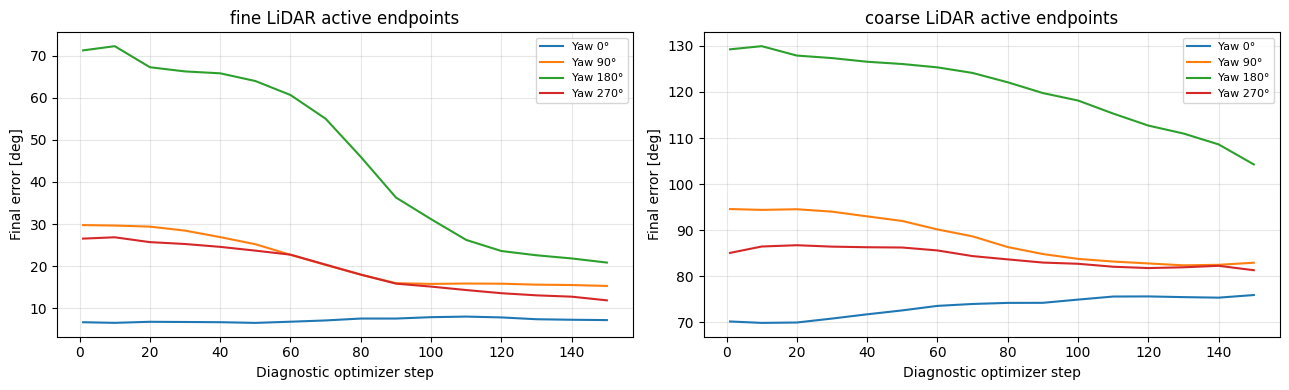

In [28]:
if precheck_history:
    fixed_df = pd.DataFrame(precheck_history)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for regime, part in fixed_df[(fixed_df.role == "active") & fixed_df.key.str.startswith("lidar")].groupby("regime"):
        for yaw, sub in part.groupby("yaw_deg"):
            line = sub.groupby("step", as_index=False).mean(numeric_only=True)
            axes[0 if regime == "fine" else 1].plot(line.step, line.mean_deg, label=f"Yaw {yaw:g}°")
    for ax, regime in zip(axes, ("fine", "coarse")):
        ax.set(title=f"{regime} LiDAR active endpoints", xlabel="Diagnostic optimizer step", ylabel="Final error [deg]")
        ax.legend(fontsize=8); ax.grid(alpha=.3)
    fig.tight_layout(); plt.show()
else:
    print("No precheck history; RUN_STOCHASTIC_CHECK=False")


## 10. Full training (same source FM51; optional exact 52 resume)

In [11]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()

In [12]:
head_params = list(fm_model.head.parameters())
feature_params = [p for block in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in block.parameters()]
assert len({id(p) for p in head_params+feature_params}) == len(head_params+feature_params)
optimizer = torch.optim.AdamW([
    {"params": head_params, "lr": HEAD_LEARNING_RATE, "name": "velocity_head"},
    {"params": feature_params, "lr": BACKBONE_LEARNING_RATE, "name": "transformer_pooler_mlp"},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS)


def run_fm52_epoch(loader, *, training, seed, regime="mixed", yaw_cap_deg=180., yaw_probability=1., max_batches=None):
    fm_model.train(training)
    generator = augmentation_generator(seed)
    yaw_randomizer = make_yaw_randomizer(yaw_cap_deg, yaw_probability)
    totals = defaultdict(float)
    examples, pending, pending_examples, updates = 0, 0, 0, 0
    started = time.perf_counter()
    if training: optimizer.zero_grad(set_to_none=True)
    def flush(n):
        for param in fm_model.parameters():
            if param.grad is not None: param.grad.mul_(1. / n)
        torch.nn.utils.clip_grad_norm_(fm_model.parameters(), GRADIENT_CLIP_NORM)
        optimizer.step(); optimizer.zero_grad(set_to_none=True)

    grad_context = torch.enable_grad() if training else torch.no_grad()
    with grad_context:
        for i, cpu_batch in enumerate(loader):
            if max_batches is not None and i >= max_batches: break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            with torch.no_grad():
                groups = weighted_regime_groups(base, generator, regime)
            batch_count = len(next(iter(base.current_calibration.values())).transform)
            for sampled_regime, subgroup in groups:
                with torch.no_grad():
                    augmented = augment_original_window(subgroup, generator, regime=sampled_regime)
                n = len(next(iter(augmented.current_calibration.values())).transform)
                loss, metrics = evaluate_paired_objective(augmented, generator=generator, frame_randomizer=yaw_randomizer, regime=sampled_regime, objective=FULL_OBJECTIVE, paired=TRAIN_PAIRED_VIEWS)
                importance = regime_loss_multiplier(sampled_regime, regime, FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT)
                if training: (loss * (n * importance)).backward()
                totals["loss_weighted"] += float(loss.detach()) * n * importance
                for key, val in metrics.items():
                    if np.isfinite(val): totals[key] += val * n
            examples += batch_count
            if training:
                pending += 1; pending_examples += batch_count
                if pending == GRADIENT_ACCUMULATION_STEPS:
                    flush(pending_examples); updates += 1; pending = pending_examples = 0
        if training and pending:
            flush(pending_examples); updates += 1
    if not examples: raise RuntimeError("Empty FM52 epoch")
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return {**{k:v/examples for k,v in totals.items()}, "num_windows": examples, "optimizer_steps": updates, "seconds":time.perf_counter()-started, "yaw_cap":yaw_cap_deg}

history_path = RUN_DIR / "fm52_full_history.csv"
history = pd.read_csv(history_path).to_dict("records") if history_path.is_file() else []
start_epoch, global_step, best_val = 0, 0, float("inf")
if RESUME_FULL_TRAINING and LAST_CHECKPOINT_PATH.is_file():
    load_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, map_location=DEVICE, restore_rng_state=True)
    saved = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    start_epoch, global_step = int(saved["epoch"]), int(saved["global_step"])
    info = saved.get("extra_state") or {}
    assert info.get("run_name") == RUN_NAME, "Cannot resume another run's optimizer"
    assert info.get("full_coarse_max_deg") == FULL_COARSE_MAX_DEG, "Coarse distribution changed"
    assert tuple(info.get("regime_weights", ())) == (FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT), "Regime weights changed"
    assert info.get("yaw_schedule") == [[int(e), float(a)] for e,a in FULL_YAW_SCHEDULE], "Yaw schedule changed"
    assert info.get("paired_views") == TRAIN_PAIRED_VIEWS, "Paired-view flag changed"
    assert info.get("equivariance_weight") == EQUIVARIANCE_LOSS_WEIGHT, "Equivariance weight changed"
    best_val = float(info.get("best_val", float("inf")))
    print("Resumed FM52 epoch", start_epoch, "optimizer step", global_step)
else:
    load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
    if history: raise RuntimeError("FM52 history exists without resumable last.pt; choose a new RUN_NAME")
    print("FM52 fresh optimizer initialized from FM51:", SOURCE_FM_CHECKPOINT)
set_coarse_angle(FULL_COARSE_MAX_DEG)


def save_fm52_checkpoint(path, epoch, metrics):
    save_training_checkpoint(path, model=fm_model, optimizer=optimizer, scheduler=scheduler,
        epoch=epoch, global_step=global_step, metrics=metrics,
        extra_state=dict(run_name=RUN_NAME, best_val=best_val, source_checkpoint=str(SOURCE_FM_CHECKPOINT),
                         full_coarse_max_deg=FULL_COARSE_MAX_DEG, regime_weights=(FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT),
                         yaw_schedule=[[int(e), float(a)] for e,a in FULL_YAW_SCHEDULE],
                         paired_views=TRAIN_PAIRED_VIEWS, equivariance_weight=EQUIVARIANCE_LOSS_WEIGHT))

if RUN_FULL_TRAINING:
    if REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING and STOCHASTIC_CHECK_PASSED is not True:
        raise RuntimeError("Stochastic preflight not passed")
    for epoch in range(start_epoch, TRAIN_EPOCHS):
        cap = training_yaw_cap(epoch+1)
        train_shuffle_generator.manual_seed(SEED+12001+epoch)
        train = run_fm52_epoch(train_loader, training=True, seed=TRAIN_AUG_SEED+100003*epoch,
                               regime=FULL_TRAIN_REGIME, yaw_cap_deg=cap, yaw_probability=FULL_YAW_PROBABILITY,
                               max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val = run_fm52_epoch(val_loader, training=False, seed=VAL_AUG_SEED,
                             regime=FULL_TRAIN_REGIME, yaw_cap_deg=VAL_YAW_MAX_DEG, yaw_probability=VAL_YAW_PROBABILITY,
                             max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        val_score = float(val["loss_weighted"])
        scheduler.step(val_score)
        global_step += int(train["optimizer_steps"])
        improved = val_score < best_val
        if improved: best_val = val_score
        row = dict(epoch=epoch+1, yaw_train_cap_deg=cap, train_loss=train["loss_weighted"], val_loss=val_score,
                   train_rotated=train.get("rotated"), val_rotated=val.get("rotated"),
                   train_equivariance=train.get("equivariance"), val_equivariance=val.get("equivariance"),
                   val_velocity=val.get("velocity"), val_endpoint=val.get("endpoint"),
                   head_lr=optimizer.param_groups[0]["lr"], backbone_lr=optimizer.param_groups[1]["lr"])
        history.append(row)
        pd.DataFrame(history).to_csv(history_path, index=False)
        if improved: save_fm52_checkpoint(BEST_CHECKPOINT_PATH, epoch+1, val)
        save_fm52_checkpoint(LAST_CHECKPOINT_PATH, epoch+1, val)
        print(f"Epoch {epoch+1:3d}/{TRAIN_EPOCHS} yaw=+/-{cap:5.1f}° train={train['loss_weighted']:.3f} val={val_score:.3f} equiv={val.get('equivariance',float('nan')):.3f} LR={optimizer.param_groups[0]['lr']:.1e}/{optimizer.param_groups[1]['lr']:.1e}" + (" BEST" if improved else ""), flush=True)
else:
    print("Full training skipped; no training weights modified by this cell.")


FM52 fresh optimizer initialized from FM51: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/best.pt


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch   1/120 yaw=+/- 10.0° train=203.679 val=324.092 equiv=47.059 LR=2.0e-05/2.0e-06 BEST
Epoch   2/120 yaw=+/- 10.0° train=186.004 val=325.450 equiv=48.036 LR=2.0e-05/2.0e-06
Epoch   3/120 yaw=+/- 20.0° train=209.892 val=324.536 equiv=47.158 LR=2.0e-05/2.0e-06
Epoch   4/120 yaw=+/- 20.0° train=195.336 val=324.150 equiv=47.064 LR=2.0e-05/2.0e-06
Epoch   5/120 yaw=+/- 30.0° train=207.542 val=323.304 equiv=47.110 LR=2.0e-05/2.0e-06 BEST
Epoch   6/120 yaw=+/- 30.0° train=207.556 val=321.289 equiv=45.726 LR=2.0e-05/2.0e-06 BEST
Epoch   7/120 yaw=+/- 40.0° train=217.381 val=320.328 equiv=45.755 LR=2.0e-05/2.0e-06 BEST
Epoch   8/120 yaw=+/- 40.0° train=229.308 val=318.193 equiv=44.394 LR=2.0e-05/2.0e-06 BEST
Epoch   9/120 yaw=+/- 50.0° train=217.394 val=320.407 equiv=45.240 LR=2.0e-05/2.0e-06
Epoch  10/120 yaw=+/- 50.0° train=205.196 val=315.628 equiv=43.291 LR=2.0e-05/2.0e-06 BEST
Epoch  11/120 yaw=+/- 60.0° train=219.970 val=315.154 equiv=42.610 LR=2.0e-05/2.0e-06 BEST
Epoch  12/120 yaw=+

## 11. Full-run curves and checkpoint selector

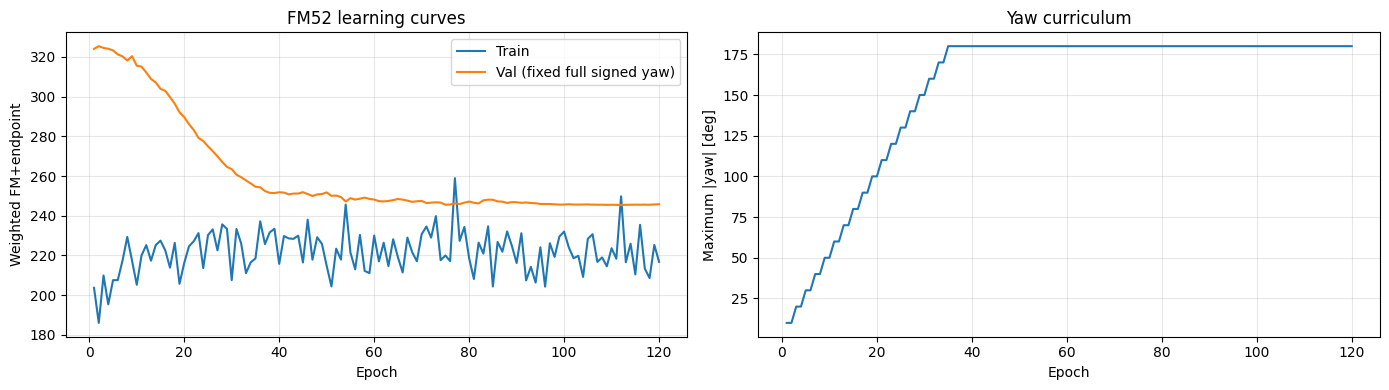

FM51 source: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/best.pt
FM52 candidate: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.9_signed_z_yaw/best.pt exists: True


In [ ]:
if history:
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(14,4))
    axes[0].plot(frame.epoch, frame.train_loss, label="Train")
    axes[0].plot(frame.epoch, frame.val_loss, label="Val (fixed full signed yaw)")
    axes[0].legend(); axes[0].set(ylabel="Weighted FM+endpoint",xlabel="Epoch",title="FM52 learning curves")
    axes[1].plot(frame.epoch, frame.yaw_train_cap_deg)
    axes[1].set(ylabel="Maximum |yaw| [deg]",xlabel="Epoch",title="Yaw curriculum")
    for ax in axes: ax.grid(alpha=.3)
    fig.tight_layout(); plt.show()

EVALUATE_FM52_FROM = "best"  # "best", "last", or "stochastic"
RUN_FIXED_YAW_EVALUATION = True
EVAL_STOCHASTIC_COARSE_MAX_DEG = STOCHASTIC_COARSE_MAX_DEG

def eval_checkpoint():
    if EVALUATE_FM52_FROM == "best": return BEST_CHECKPOINT_PATH
    if EVALUATE_FM52_FROM == "last": return LAST_CHECKPOINT_PATH
    if EVALUATE_FM52_FROM == "stochastic": return RUN_DIR / f"stochastic_yaw_{EVAL_STOCHASTIC_COARSE_MAX_DEG:g}deg.pt"
    raise ValueError(EVALUATE_FM52_FROM)


def load_fm52_model(path):
    if not path.is_file(): raise FileNotFoundError(path)
    model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=DTYPE)
    if path.name.startswith("stochastic_yaw_"):
        model.load_state_dict(torch.load(path, map_location="cpu", weights_only=False)["model_state_dict"], strict=True)
    else:
        load_training_checkpoint(path, model=model, map_location=DEVICE, restore_rng_state=False)
    return model.eval().requires_grad_(False)

print("FM51 source:", SOURCE_FM_CHECKPOINT)
print("FM52 candidate:", eval_checkpoint(), "exists:", eval_checkpoint().is_file())


## 12. Fixed yaw × controlled angle-grid validation against the unmodified FM51 source

In [15]:
# Fixed and identical between models, independent of the training distribution.
EVAL_FAULT_KEYS = CALIBRATION_KEYS
EVAL_ANGLE_BINS = ((0.,0.),(0.,5.),(5.,15.),(15.,30.),(30.,60.),(60.,90.),(90.,120.),(120.,150.),(150.,179.))
EVAL_YAW_DEGREES = (0., 45., 90., 135., 180., 225., 270., 315.)
EVAL_WINDOWS_PER_KEY = 3  # 9 bins * 3 keys * 3 windows * 8 yaws = 648/model; reduce for smoke testing.
EVAL_SEED = VAL_AUG_SEED + 950000
EVAL_OUTPUT = RUN_DIR / "fm52_fixed_yaw_angle_comparison.csv"

@torch.no_grad()
def build_yaw_angular_cases():
    case_list = []
    indexes = np.unique(np.linspace(0, len(val_dataset)-1, EVAL_WINDOWS_PER_KEY).round().astype(int))
    for bin_index, (low, high) in enumerate(EVAL_ANGLE_BINS):
        for key_index, key in enumerate(EVAL_FAULT_KEYS):
            for item_index, window_index in enumerate(indexes):
                rng = augmentation_generator(EVAL_SEED + 100000*bin_index+10000*key_index+item_index)
                base = window_batch_to(collate_windows([val_dataset[int(window_index)]]), DEVICE, dtype=DTYPE)
                physical = physical_augmenter(base, generator=rng).augmented_window
                reference = physical.current_calibration
                sample = next(iter(reference.values())).transform
                xi = {k: sample.new_zeros(1,6) for k in reference}
                tau = {k: torch.zeros_like(s.time_offset) for k,s in reference.items()}
                axis = torch.randn(3, device=DEVICE, dtype=DTYPE, generator=rng)
                axis = axis / torch.linalg.vector_norm(axis).clamp_min(1e-12)
                angle = 0.0 if low == high == 0. else float(low+(high-low)*torch.rand((),device=DEVICE,generator=rng))
                xi[key][0,:3] = axis*np.deg2rad(angle)
                wrong = clone_with_current_calibration(physical, apply_prior_perturbation(reference, xi, tau))
                for yaw in EVAL_YAW_DEGREES:
                    rotated,_ = rotate_window_fixed_yaw(wrong, yaw)
                    case_list.append(dict(window=window_batch_to(rotated,torch.device("cpu"),dtype=DTYPE), yaw_deg=yaw,
                                          bin="0°" if low == high == 0. else f"{low:g}–{high:g}°", low=low, high=high, fault_key=key,
                                          initial_deg=angle, window_index=int(window_index)))
    return case_list

@torch.no_grad()
def score_yaw_angular_cases(model, cases, label):
    rows=[]
    for case in cases:
        window=window_batch_to(case["window"],DEVICE,dtype=DTYPE)
        pred=model_predictions(model,window,steps=FM_INTEGRATION_STEPS)
        for key in CALIBRATION_KEYS:
            corrected=se3_exp(pred.predictions[key].delta_xi) @ window.current_calibration[key].transform
            desired=window.targets[key].next_transform
            R=desired[:,:3,:3] @ corrected[:,:3,:3].transpose(-1,-2)
            sine=.5*torch.linalg.vector_norm(torch.stack((R[:,2,1]-R[:,1,2],R[:,0,2]-R[:,2,0],R[:,1,0]-R[:,0,1]),-1),dim=-1)
            cosine=.5*(R.diagonal(dim1=-2,dim2=-1).sum(dim=-1)-1)
            error=float(torch.rad2deg(torch.atan2(sine,cosine)).mean())
            rows.append(dict(model=label,bin=case["bin"],bin_low=case["low"],fault_key=case["fault_key"],
                             measured_key=key,active=(key==case["fault_key"]),yaw_deg=case["yaw_deg"],
                             window_index=case["window_index"],initial_deg=case["initial_deg"],final_deg=error,
                             improved=bool(error<case["initial_deg"]) if key==case["fault_key"] else False))
    return pd.DataFrame(rows)

if RUN_FIXED_YAW_EVALUATION and eval_checkpoint().is_file():
    fixed_cases=build_yaw_angular_cases()
    results=[]
    for label,path in (("FM51 source",SOURCE_FM_CHECKPOINT),("FM52 yaw",eval_checkpoint())):
        model=load_fm52_model(path)
        results.append(score_yaw_angular_cases(model,fixed_cases,label))
        del model; gc.collect()
        if DEVICE.type=="cuda": torch.cuda.empty_cache()
    yaw_angular_results=pd.concat(results,ignore_index=True)
    yaw_angular_results.to_csv(EVAL_OUTPUT,index=False)
    display(yaw_angular_results[yaw_angular_results.active].groupby(["model","yaw_deg","bin"],as_index=False).agg(n=("final_deg","size"),final_mean_deg=("final_deg","mean"),improved_fraction=("improved","mean")).round(3))
else:
    print("Fixed yaw×angle evaluation skipped (no candidate or disabled)")


,model,yaw_deg,bin,n,final_mean_deg,improved_fraction
0,FM51 source,0.0,0°,9,1.087,0.000
1,FM51 source,0.0,0–5°,9,2.008,0.778
2,FM51 source,0.0,120–150°,9,104.327,0.778
3,FM51 source,0.0,150–179°,9,135.365,0.444
4,FM51 source,0.0,15–30°,9,7.342,1.000
...,...,...,...,...,...,...
139,FM52 yaw,315.0,15–30°,9,14.226,0.889
140,FM52 yaw,315.0,30–60°,9,23.223,1.000
141,FM52 yaw,315.0,5–15°,9,7.225,0.778
142,FM52 yaw,315.0,60–90°,9,33.393,1.000


## 13. Yaw/angle sensitivity plots and healthy sensor drift

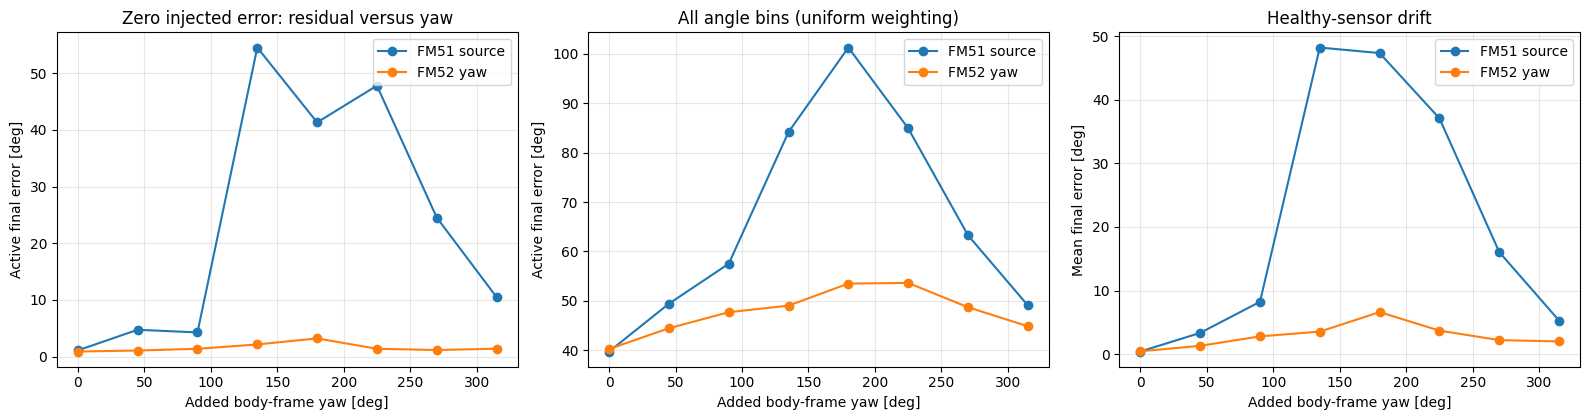

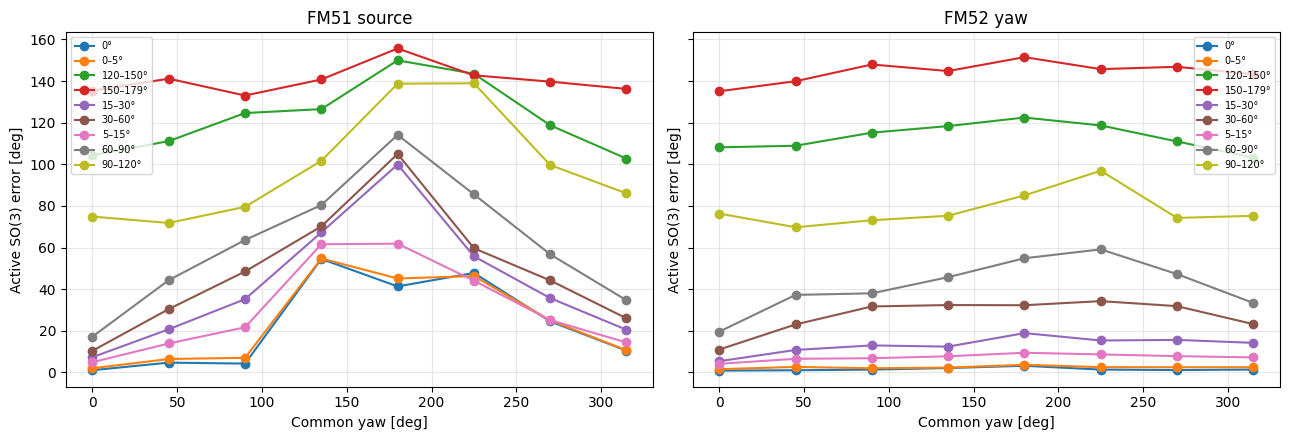

In [16]:
if "yaw_angular_results" in globals() and not yaw_angular_results.empty:
    df=yaw_angular_results
    fig,axes=plt.subplots(1,3,figsize=(16,4.3))
    zero=df[(df.active) & (df.bin=="0°")]
    for label,g in zero.groupby("model"):
        p=g.groupby("yaw_deg",as_index=False).final_deg.mean()
        axes[0].plot(p.yaw_deg,p.final_deg,"-o",label=label)
    axes[0].set(title="Zero injected error: residual versus yaw",xlabel="Added body-frame yaw [deg]",ylabel="Active final error [deg]")
    group=df[df.active].groupby(["model","yaw_deg"],as_index=False).agg(final=("final_deg","mean"),success=("improved","mean"))
    for label,g in group.groupby("model"):
        axes[1].plot(g.yaw_deg,g.final,"-o",label=label)
    axes[1].set(title="All angle bins (uniform weighting)",xlabel="Added body-frame yaw [deg]",ylabel="Active final error [deg]")
    healthy=df[~df.active].groupby(["model","yaw_deg"],as_index=False).final_deg.mean()
    for label,g in healthy.groupby("model"):
        axes[2].plot(g.yaw_deg,g.final_deg,"-o",label=label)
    axes[2].set(title="Healthy-sensor drift",xlabel="Added body-frame yaw [deg]",ylabel="Mean final error [deg]")
    for ax in axes: ax.legend();ax.grid(alpha=.3)
    fig.tight_layout();plt.show()
    p=df[df.active].groupby(["model","bin","yaw_deg"],as_index=False).final_deg.mean()
    fig,axes=plt.subplots(1,2,figsize=(13,4.5),sharey=True)
    for ax,(label,part) in zip(axes,p.groupby("model")):
        for angle_bin,sub in part.groupby("bin"):
            ax.plot(sub.yaw_deg,sub.final_deg,"-o",label=angle_bin)
        ax.set(title=label,xlabel="Common yaw [deg]",ylabel="Active SO(3) error [deg]")
        ax.grid(alpha=.3); ax.legend(fontsize=7)
    fig.tight_layout();plt.show()
else: print("No yaw/angle results yet")


## 14. Interpretation and next test

**Success criteria:** (a) FM52’s active LiDAR error at yaw 0° remains at least competitive with FM51; (b) large peaks across yaw decrease substantially, notably 0°/45°/315°; (c) low-error corrections are not destroyed; (d) healthy calibration drift remains low. The fixed yaw evaluation includes 0–179° faults, so near-180° recovery can be monitored independently from frame invariance.

**Important:** A common-frame Z-yaw test evaluates *representation robustness*, not whether New College scan-to-scan odometry is accurate enough or temporally aligned. Once FM52 has been selected on KAIST validation, compare FM51 and FM52 on New College using the *same* clock-shift setting and sensor configuration without training against that dataset.